# Aprendizaje Automático
#### Segundo cuatrimestre 2026

## Evaluación de modelos

#### Bibliografía: 
* The Elements of Statistical Learning, Trevor Hastie, Robert Tibshirani, Jerome Friedman. Capítulo 7.
* Pattern Recognition and Machine Learning, Christopher M. Bishop. Secciones 1.5.5 y 3.2.


Papers:
*  False-positive psychology: Undisclosed flexibility in data collection and analysis allows presenting anything as significant. Simmons, J. P., Nelson, L. D., & Simonsohn, U. 2011.
*  Double dipping in machine learning: Problems and solutions. Ball, T. M., Squeglia, L. M., Tapert, S. F., & Paulus, M. P. 2020. 
*  The need to approximate the use-case in clinical machine learning. Saeb, S., Lonini, L., Jayaraman, A., Mohr, D. C., & Kording, K. P. 2017.

### Evaluación de modelos

¿Cuáles son los objetivos típicos de la evaluación de modelos de aprendizaje automático (según el libro)?

* Comparación justa entre diferentes modelos para elegir el mejor (selección de modelos, *model selection*).
    * Notar que esto incluye optimización de hiperparámetros. ¿Por qué?
* Estimar el error de generalización del modelo seleccionado en datos nuevos (estimación del rendimiento, *model assessment*).

### Evaluación de modelos

Vayamos al final de la historia: ¿Cuál es la forma típica de entrenar y evaluar modelos?

Antes que nada: hay varias nomenclaturas para los conjuntos de datos. Acá usaremos: entrenamiento (train), validación (validation) y prueba (test).

1. Dividir los datos en conjuntos de entrenamiento y prueba. A partir de acá, prueba queda "guardado" para la evaluación final.
1. Ajustar uno o varios modelos en el conjunto de entrenamiento.
    * Dentro del conjunto de entrenamiento, hacer validación cruzada independientemente de si hacemos selección de modelos o no.
1. En caso de haber comparado varios modelos, elegir el mejor según el rendimiento en validación cruzada.
1. Ajustar el modelo elegido con todo el conjunto de entrenamiento.
1. Evaluar el rendimiento del modelo en el conjunto de prueba.

Surgen varias preguntas:

* ¿Cuándo hacemos la primera división?¿Antes o después de explorar los datos, hacer limpieza, ingeniería de características, etc.?
* ¿Cuándo podemos *relajar* esta receta?
* ¿Qué cambia o dónde entra la optimización de hiperparámetros en este esquema?
* ¿Dónde entra la complejidad del modelo y la navaja de Ockham en todo esto?

Vamos a ver que esta receta no es arbitraria.

In [1]:
import numpy as np
import pandas as pd

In [2]:
n_hiper_params = 3
number_of_values_per_param = 10
total_combinations = number_of_values_per_param ** n_hiper_params
print(f"Total combinations: {total_combinations}")

Total combinations: 1000


Estimemos la probabilidad de que un modelo dé resultados "buenos" por azar. En particular, la probabilidad de que un modelo dé resultados "más altos" en los cinco folds.

In [3]:
np.random.seed(42)
real_performance = 0.8
std_dev = 0.025
number_of_folds = 5

df_results = pd.DataFrame(np.random.normal(real_performance, std_dev, size=(total_combinations, number_of_folds)),
                          columns=[f"fold_{i+1}" for i in range(number_of_folds)])

folds_columns = [f"fold_{i+1}" for i in range(number_of_folds)]
df_results['mean_performance'] = df_results[folds_columns].mean(axis=1)
df_results['std_performance'] = df_results[folds_columns].std(axis=1)
df_results['number_of_folds_above_real_performance'] = (df_results[folds_columns] > real_performance).sum(axis=1)


In [5]:
df_results

,fold_1,fold_2,fold_3,fold_4,fold_5,mean_performance,std_performance,number_of_folds_above_real_performance
0,0.812418,0.796543,0.816192,0.838076,0.794146,0.811475,0.017706,3
1,0.794147,0.839480,0.819186,0.788263,0.813564,0.810928,0.020529,3
2,0.788415,0.788357,0.806049,0.752168,0.756877,0.778373,0.022996,1
3,0.785943,0.774679,0.807856,0.777299,0.764692,0.782094,0.016273,1
4,0.836641,0.794356,0.801688,0.764381,0.786390,0.796691,0.026346,2
...,...,...,...,...,...,...,...,...
995,0.765654,0.834462,0.802896,0.809740,0.744489,0.791448,0.036008,3
996,0.770051,0.822177,0.807169,0.796320,0.814121,0.801968,0.020210,3
997,0.840895,0.794474,0.801734,0.804815,0.859803,0.820344,0.028443,4
998,0.747516,0.817081,0.797130,0.814169,0.783566,0.791892,0.028270,2


In [6]:
df_results.iloc[df_results['mean_performance'].idxmax()]

fold_1                                    0.850152
fold_2                                    0.851538
fold_3                                    0.830209
fold_4                                    0.825602
fold_5                                    0.814813
mean_performance                          0.834463
std_performance                           0.015972
number_of_folds_above_real_performance    5.000000
Name: 299, dtype: float64

<Axes: >

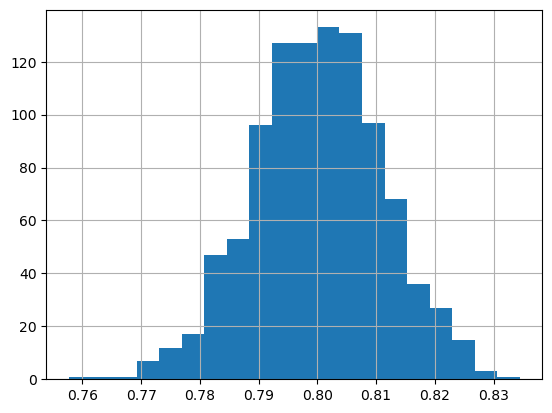

In [7]:
df_results.mean_performance.hist(bins=20)

In [7]:
df_results.query('number_of_folds_above_real_performance == @number_of_folds')

,fold_1,fold_2,fold_3,fold_4,fold_5,mean_performance,std_performance,number_of_folds_above_real_performance
74,0.800613,0.812450,0.836279,0.823982,0.853830,0.825431,0.020680,5
123,0.803231,0.802735,0.818144,0.812025,0.805597,0.808346,0.006610,5
147,0.811815,0.806401,0.824567,0.841637,0.825359,0.821956,0.013698,5
178,0.820512,0.812682,0.826667,0.829232,0.834554,0.824729,0.008418,5
191,0.827932,0.808568,0.811419,0.814244,0.811193,0.814671,0.007681,5
233,0.860994,0.834607,0.814098,0.814869,0.821335,0.829181,0.019592,5
268,0.804014,0.800076,0.810923,0.829766,0.823739,0.813704,0.012709,5
283,0.823196,0.801425,0.806715,0.838212,0.812696,0.816449,0.014609,5
290,0.807721,0.842555,0.806019,0.865042,0.814138,0.827095,0.025819,5
299,0.850152,0.851538,0.830209,0.825602,0.814813,0.834463,0.015972,5


¿Y qué chances hay de que una nueva medición "corrija" el resultado?

In [8]:
np.random.seed(42)
df_results['new_performance'] = np.random.normal(real_performance, std_dev, size=(len(df_results)))

In [10]:
df_results.iloc[df_results['mean_performance'].idxmin()]

fold_1                                    0.727144
fold_2                                    0.813081
fold_3                                    0.769492
fold_4                                    0.749567
fold_5                                    0.729192
mean_performance                          0.757695
std_performance                           0.035421
number_of_folds_above_real_performance    1.000000
new_performance                           0.809430
Name: 927, dtype: float64

In [11]:
query = 'number_of_folds_above_real_performance == @number_of_folds'
df_results.query(query)[['mean_performance', 'std_performance','new_performance']]

,mean_performance,std_performance,new_performance
74,0.825431,0.020680,0.734506
123,0.808346,0.006610,0.764954
147,0.821956,0.013698,0.766989
178,0.824729,0.008418,0.793384
191,0.814671,0.007681,0.821410
233,0.829181,0.019592,0.783710
268,0.813704,0.012709,0.788999
283,0.816449,0.014609,0.769055
290,0.827095,0.025819,0.794797
299,0.834463,0.015972,0.815741


### Pérdida y error

#### Regresión

* $X \in \mathbb{R}^p$ es un vector de atributos predictivos.
* $Y \in \mathbb{R}$ es un valor continuo a predecir.
* $P(X,Y)$ es su distribución conjunta.
* $\hat{f}(X)$ es un modelo de predicción entrenado con un conjunto de datos $\tau = \{(x_i, y_i)\}_{i=1}^N$.

Para obtener $\hat{f}(X)$, se minimiza una función de pérdida $L(Y, \hat{f}(X))$ en el conjunto de entrenamiento:
$$ L(Y, \hat{f}(X)) = \begin{cases}  
                    (Y - \hat{f}(X))^2 \text{  (Error cuadrático)} \\
                    |(Y - \hat{f}(X)) | \text{  (Error absoluto)} 
                    \end{cases}$$


### Pérdida y error

#### Teoría de la decisión

Buscamos una función $f(X)$ que prediga $Y$ dado $X$. La función de pérdida típica es la pérdida cuadrática, $L(Y,f(X)) = (Y - f(X))^2$. Entonces:

$$ EPE(f) = E[L(Y,f(X))] = E[(Y - f(X))^2] $$

Que podemos reescribir como

$$ EPE(f) = \int (y - f(x))^2 p(x,y) dy dx  $$

Condicionando, 

$$ EPE(f) = \int (y - f(x))^2 p(y|x) p(x) dy dx $$

$$ EPE(f) = E_{X}E_{Y|X} ([Y - f(X)]^2|X) $$


### Pérdida y error

#### Teoría de la decisión

$$ EPE(f) = \int (y - f(x))^2 p(y|x) p(x) dy dx $$

$$ EPE(f) = E_{X}E_{Y|X} ([Y - f(X)]^2|X) $$

Basta con minimizar punto a punto, por lo que buscamos un $c$ tal que:

$$ f(x) = \arg\min_{c \in \mathbb{R}} E_{Y|X} ([Y - c]^2|X = x) $$

Cuya solución es

$$f(x) = E(Y|X = x) $$

que se conoce como la función de regresión.

¿Qué quiere decir? La mejor predicción de $Y$ en un punto $X = x$ es la media condicional (cuando es medido por el error cuadrático).

### Pérdida y error

Misma idea, pero cambiemos la notación un poco. Vamos al Bishop.

$$ EPE(f) = E[L(Y,f(X))] = \int \int L(y, f(x)) p(x,y) dx dy  $$

Para el error cuadrático, queda:

$$ E[L(Y,f(X))] = \int \int (y - f(x))^2 p(x,y) dx dy  $$

Hay que elegir $f$ para minimizar $E[L(Y,f(X))]$. Esto se puede resolver usando una técnica que se llama *cálculo variacional*.

$$ \frac{\delta E[L]}{\delta f(x)}  = \int 2 (f(x) - y) p(x,y) dy = 0 $$

### Pérdida y error

$$ \frac{\delta E[L]}{\delta f(x)}  = \int 2 (f(x) - y) p(x,y) dy = 0 $$

Como $f(x)$ no depende de $y$, podemos sacarlo de la integral y despejar:

$$ f(x) \int p(x,y) dy = \int y p(x,y) dy  $$

$\int p(x,y) dy = p(x)$, por lo que queda:

$$ f(x) = \frac{\int y p(x,y) dy}{p(x)} $$

$$ f(x) = \int y p(y|x) dy = E_Y[Y|X=x] $$

donde queda explícito sobre qué estamos tomando la esperanza. Vamos a usar esta notación de ahora en más:

$$ f(X) = E_Y[Y|X] \text{ ó }  f(X) = E[Y|X]$$

### Descomposición sesgo-varianza

Si a $(f(x) - y)^2$ le sumamos y restamos $E_{Y}[Y|X=x]$ y expandimos el cuadrado, tenemos: 

$$(f(x) - y)^2 = (f(x) - E_{Y}[Y|X=x])^2 + (E_{Y}[Y|X=x] - y)^2 + 2(f(x) - E_{Y}[Y|X=x])(E_{Y}[Y|X=x] - y) $$

Cuando tomamos esperanza con respecto a $Y$, el último término desaparece porque $E_{Y}[(E_{Y}[Y|X=x] - Y)|X=x] = 0$. Por lo tanto, queda la descomposición:

$$ E[L] = \int (f(x) - E_{Y}[Y|X=x])^2 p(x) dx + \int (E_{Y}[Y|X=x] - y)^2 p(x,y) dx dy $$

El primer término se minimiza cuando $f(x) = E_{Y}[Y|X=x]$. El segundo término no depende de $f$ y es la varianza inherente al problema de predicción. Es el famoso **error irreducible**.


### Descomposición sesgo-varianza

$$ E[L] = \int (f(x) - E_{Y}[Y|X=x])^2 p(x) dx + \int (E_{Y}[Y|X=x] - y)^2 p(x,y) dx dy $$

Pero el error también depende del conjunto de entrenamiento $\tau$ que usamos para estimar $f(x)$. Por lo tanto, podemos considerar a $f(x)$ como una variable aleatoria que depende de $\tau$, $f(x; \tau)$. Entonces, igual que hicimos antes, en el primer término podemos sumar y restar $E_{\tau}[f(x; \tau)]$ y expandir el cuadrado:

$$ (f(x;\tau) - E_{Y}[Y|X=x])^2 = (f(x;\tau) - E_{\tau}[f(x; \tau)])^2 + (E_{\tau}[f(x; \tau)] - E_{Y}[Y|X=x])^2 + \\ 
2(f(x;\tau) - E_{\tau}[f(x; \tau)])(E_{\tau}[f(x; \tau)] - E_{Y}[Y|X=x]) $$

### Descomposición sesgo-varianza

$$ (f(x;\tau) - E_{Y}[Y|X=x])^2 = (f(x;\tau) - E_{\tau}[f(x; \tau)])^2 + (E_{\tau}[f(x; \tau)] - E_{Y}[Y|X=x])^2 + \\ 
2(f(x;\tau) - E_{\tau}[f(x; \tau)])(E_{\tau}[f(x; \tau)] - E_{Y}[Y|X=x]) $$

Nuevamente, el término cruzado desaparece porque si tomamos esperanza con respecto a $\tau$, $E_{\tau}[(f(x;\tau) - E_{\tau}[f(x; \tau)])] = 0$. Por lo tanto, queda la descomposición:

$$ E_{\tau}[(f(x;\tau) - E_{Y}[Y|X=x])^2] = E_{\tau}[(f(x;\tau) - E_{\tau}[f(x; \tau)])^2 + (E_{\tau}[f(x; \tau)] - E_{Y}[Y|X=x])^2]$$

$$ E_{\tau}[(f(x;\tau) - E_{Y}[Y|X=x])^2] = E_{\tau}[(f(x;\tau) - E_{\tau}[f(x; \tau)])^2] + (E_{\tau}[f(x; \tau)] - E_{Y}[Y|X=x])^2$$

$$ E_{\tau}[(f(x;\tau) - E_{Y}[Y|X=x])^2] = \underbrace{E_{\tau}[(f(x;\tau) - E_{\tau}[f(x; \tau)])^2]}_{\text{Varianza}} + \underbrace{(E_{\tau}[f(x; \tau)] - E_{Y}[Y|X=x])^2}_{\text{Sesgo}^2}$$

El primer término, la varianza, mide qué tanto varían las soluciones para conjuntos de datos individuales alrededor de su promedio, y por lo tanto mide qué tan sensible es la función $f(x; \tau)$ a la elección particular del conjunto de datos.

El segundo término, el sesgo, mide qué tanto difiere el promedio de las predicciones sobre todos los conjuntos de entrenamiento $\tau$ de la función de regresión deseada.

### Descomposición sesgo-varianza

Volviendo a la descomposición original del error, tenemos:

$$ E_{\tau}\big[E[L]\big] = \text{sesgo}^2 + \text{varianza} + \text{error irreducible} $$

donde cada término es la versión puntual integrada sobre $p(x)$:

$$ \text{sesgo}^2 = \int (E_{\tau}[f(x; \tau)] - E_{Y}[Y|X=x])^2 p(x) dx $$

$$ \text{varianza} = \int E_{\tau}[(f(x;\tau) - E_{\tau}[f(x; \tau)])^2] p(x) dx $$

$$ \text{error irreducible} = \int (E_{Y}[Y|X=x] - y)^2 p(x,y) dx dy $$

<img src="Figuras/Bias-Variance.png" alt="Figura 1" width="800" />

In [4]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_regression

# from sklearn.linear_model import Ridge

In [ ]:
n_features = 50
n_informative = 5
noise_std = 20
n_train = 70
n_test = 200

# Un único vector de coeficientes verdaderos: f queda fija en todas las repeticiones
_, _, true_coef = make_regression(n_samples=1, n_features=n_features,
                                  n_informative=n_informative, coef=True, random_state=0)

rng = np.random.default_rng(42)

def sample_dataset(n_samples):
    # Misma distribución que make_regression: X ~ N(0, I), y = X @ coef + ruido gaussiano
    X = rng.standard_normal((n_samples, n_features))
    y = X @ true_coef + noise_std * rng.standard_normal(n_samples)
    return X, y

X_test, y_test = sample_dataset(n_test)

In [80]:
# U,D,VT = np.linalg.svd(X_train, full_matrices=False)


In [81]:
alphas = np.logspace(-5, 5, 51)
n_repetitions = 100

train_mses = np.zeros((n_repetitions, len(alphas)))
test_mses = np.zeros((n_repetitions, len(alphas)))
dfs = np.zeros((n_repetitions, len(alphas)))

# Acumuladores para estimar E_tau[f_hat(x)] y Var_tau[f_hat(x)] en cada punto de test,
# sin guardar todas las predicciones (serían n_repetitions x len(alphas) x n_test)
sum_test_preds = np.zeros((len(alphas), n_test))
sum_sq_test_preds = np.zeros((len(alphas), n_test))

for i in range(n_repetitions):
    X_train, y_train = sample_dataset(n_train)

    # Ridge no penaliza el intercept: se centran X e y, se ajustan los coeficientes
    # y el intercepto se recupera al final. La SVD se calcula una sola vez por tau.
    X_train_mean = X_train.mean(axis=0)
    y_train_mean = y_train.mean()
    U, D, VT = np.linalg.svd(X_train - X_train_mean, full_matrices=False)
    Ut_y = U.T @ (y_train - y_train_mean)

    for j, alpha_ in enumerate(alphas):
        # Solución cerrada de Ridge: beta = V diag(d / (d^2 + alpha)) U^T y
        coef = VT.T @ (D / (D**2 + alpha_) * Ut_y)
        intercept = y_train_mean - X_train_mean @ coef

        y_train_pred = X_train @ coef + intercept
        y_test_pred = X_test @ coef + intercept

        train_mses[i, j] = np.mean((y_train - y_train_pred)**2) ### estas son la curvas azules
        test_mses[i, j] = np.mean((y_test - y_test_pred)**2) ### estas son la curvas rojas
        dfs[i, j] = np.sum(D**2 / (D**2 + alpha_)) ### si alpha es cero, la cantidad de grados de libertad es la cantidad de parámetros del modelo

        sum_test_preds[j] += y_test_pred
        sum_sq_test_preds[j] += y_test_pred**2

(0.0, 6000.0)

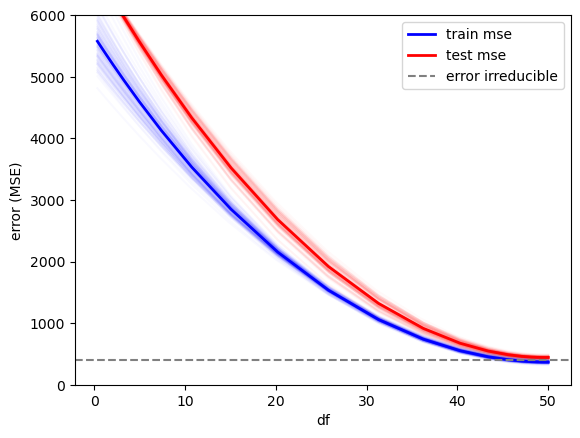

In [83]:
mean_dfs = dfs.mean(axis=0)

# Curvas finas: err de entrenamiento y Err_tau para cada tau. Curvas gruesas: promedio sobre tau (estima Err)
for i in range(n_repetitions):
    plt.plot(dfs[i], train_mses[i], color='blue', alpha=0.025)
    plt.plot(dfs[i], test_mses[i], color='red', alpha=0.025)
    # plt.plot(-np.log10(alphas), train_mses[i], color='blue', alpha=0.05)
    # plt.plot(-np.log10(alphas), test_mses[i], color='red', alpha=0.05)

plt.plot(mean_dfs, train_mses.mean(axis=0), color='blue', label='train mse', linewidth=2)
plt.plot(mean_dfs, test_mses.mean(axis=0), color='red', label='test mse', linewidth=2)
plt.axhline(noise_std**2, color='gray', linestyle='--', label='error irreducible')

plt.xlabel('df')
plt.ylabel('error (MSE)')
plt.legend()
plt.ylim(0,6000)

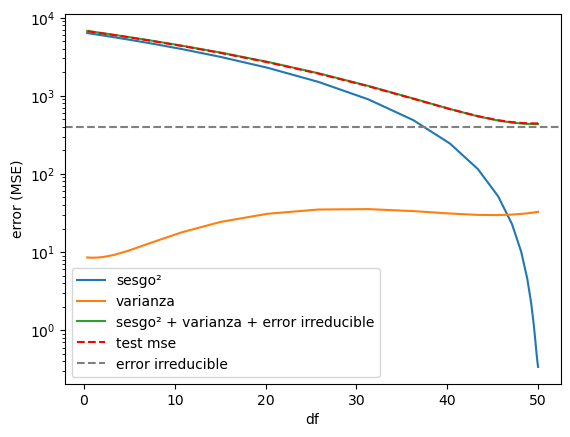

In [84]:
f_test = X_test @ true_coef  # f verdadera en los puntos de test, sin ruido

mean_test_preds = sum_test_preds / n_repetitions

# Var = E[f_hat^2] - E[f_hat]^2, punto a punto, sobre los tau
var_test_preds = sum_sq_test_preds / n_repetitions - mean_test_preds**2

# Promedio sobre los x de test: las integrales sobre p(x) de las slides
bias_squared = ((mean_test_preds - f_test)**2).mean(axis=1)
variance = var_test_preds.mean(axis=1)
irreducible_error = noise_std**2

plt.plot(mean_dfs, bias_squared, label='sesgo²')
plt.plot(mean_dfs, variance, label='varianza')
plt.plot(mean_dfs, bias_squared + variance + irreducible_error, label='sesgo² + varianza + error irreducible')
plt.plot(mean_dfs, test_mses.mean(axis=0), color='red', linestyle='--', label='test mse')
plt.axhline(irreducible_error, color='gray', linestyle='--', label='error irreducible')

plt.yscale('log')
plt.xlabel('df')
plt.ylabel('error (MSE)')
plt.legend()

### Descomposición sesgo-varianza

$$ \text{sesgo}^2 = \int (E_{\tau}[f(x; \tau)] - E_{Y}[Y|X=x])^2 p(x) dx $$

$$ \text{varianza} = \int E_{\tau}[(f(x;\tau) - E_{\tau}[f(x; \tau)])^2] p(x) dx $$

$$ \text{error irreducible} = \int (E_{Y}[Y|X=x] - y)^2 p(x,y) dx dy $$

### Errores

El **error de prueba** o de generalización (*test error* o *generalization error*) es el error esperado en datos nuevos no vistos durante el entrenamiento para un conjunto de entrenamiento $\tau$ dado:

$$Err_{\tau} = E[L(Y, \hat{f}(X))|\tau] $$

Como el error depende del conjunto de entrenamiento $\tau$ usado para ajustar el modelo $\hat{f}(X)$, podríamos promediar sobre todos los conjuntos de entrenamiento posibles para obtener el **error de prueba esperado**:

$$Err = E[L(Y, \hat{f}(X))] = E[Err_{\tau}] $$

El error de entrenamiento (*training error*) es el error medido en el mismo conjunto de datos usado para ajustar el modelo:

$$ \overline{err} = \frac{1}{N} \sum_{i=1}^{N} L(y_i, \hat{f}(x_i)) $$

¿Cuáles acabamos de estimar?¿Cuál descomponemos en sesgo y varianza?

### Descomposición sesgo-varianza

Veamos la descomposición sesgo-varianza para algunos casos específicos. Por simplicidad, toda la notación se hará condicional en un punto $X = x_0$ y la aleatoriedad será sólo $Y$ (no en el conjunto de entrenamiento $\tau$ completo, incluyendo también los $X$).

**Regresión lineal por cuadrados mínimos**

El error en un punto $x_0$ es:

$$ Err(x_0) = E [(Y -  \hat{f}(X))^2 | X = x_0] $$

Asumimos que $Y = f(X) + \epsilon$, con $E[\epsilon] = 0$ y $Var(\epsilon) = \sigma_{\epsilon}^2$. Entonces,

$$ Err(x_0) = E [(f(x_0) + \epsilon -  \hat{f}(x_0))^2] $$

Expandimos el cuadrado y tomamos esperanza. El término cruzado entre $\epsilon$ y $\hat{f}(x_0)$ desaparece porque $E[\epsilon] = 0$ y $\epsilon$ es independiente de $\hat{f}(x_0)$. Queda:

$$ Err(x_0) = E [(f(x_0) -  \hat{f}(x_0))^2] + E[\epsilon^2] $$



### Descomposición sesgo-varianza

**Regresión lineal por cuadrados mínimos**

$$ Err(x_0) = E [(f(x_0) -  \hat{f}(x_0))^2] + E[\epsilon^2] $$

$$ Err(x_0) = E [(f(x_0) -  \hat{f}(x_0))^2] + \sigma_{\epsilon}^2 $$

Ahora, mismo truco: sumamos y restamos $E[\hat{f}(x_0)]$ dentro del primer término

$$ Err(x_0) = E [((f(x_0) -  E[\hat{f}(x_0)]) + (E[\hat{f}(x_0)] -  \hat{f}(x_0)))^2] + \sigma_{\epsilon}^2 $$

y expandimos el cuadrado. Nuevamente, el cruzado desaparece:

$$ Err(x_0) = E [(f(x_0) -  E[\hat{f}(x_0)])^2] + E[(E[\hat{f}(x_0)] -  \hat{f}(x_0))^2] + \sigma_{\epsilon}^2 $$

$$ Err(x_0) = \underbrace{(f(x_0) -  E[\hat{f}(x_0)])^2}_{\text{Sesgo}^2} + \underbrace{E[(E[\hat{f}(x_0)] -  \hat{f}(x_0))^2]}_{\text{Varianza}} + \underbrace{\sigma_{\epsilon}^2}_{\text{Error irreducible}} $$

### Descomposición sesgo-varianza

**Regresión lineal por cuadrados mínimos**

$$ Err(x_0) = \underbrace{(f(x_0) -  E[\hat{f}(x_0)])^2}_{\text{Sesgo}^2} + \underbrace{E[(E[\hat{f}(x_0)] -  \hat{f}(x_0))^2]}_{\text{Varianza}} + \underbrace{\sigma_{\epsilon}^2}_{\text{Error irreducible}} $$

Pero todavía no usamos todas las propiedades de la regresión lineal por cuadrados mínimos. Recordemos que:

$$ \hat{f}(x_0) = x_0^T \hat{\beta} $$

$$ \hat{f}(x_0) = x_0^T (\textbf{X}^T \textbf{X})^{-1} \textbf{X}^T \textbf{y} $$

Hay que calcular su varianza. Se puede escribir

$$ \hat{f}(x_0) = \textbf{h}(x_0)^T \textbf{y} $$

donde $\textbf{h}(x_0) = \textbf{X}(\textbf{X}^T \textbf{X})^{-1} x_0$. Entonces, 

$$var(\hat{f}(x_0)) = var(\textbf{h}(x_0)^T \textbf{y})$$




### Descomposición sesgo-varianza

**Regresión lineal por cuadrados mínimos**

$$ Err(x_0) = \underbrace{(f(x_0) -  E[\hat{f}(x_0)])^2}_{\text{Sesgo}^2} + \underbrace{E[(E[\hat{f}(x_0)] -  \hat{f}(x_0))^2]}_{\text{Varianza}} + \underbrace{\sigma_{\epsilon}^2}_{\text{Error irreducible}} $$

$$var(\hat{f}(x_0)) = var(\textbf{h}(x_0)^T \textbf{y})$$

Pero como asumimos que la aleatoriedad solo viene de $Y$, 

$$var(\hat{f}(x_0)) = \textbf{h}(x_0)^T \textbf{h}(x_0) \sigma_{\epsilon}^2 $$

$$var(\hat{f}(x_0)) = ||\textbf{h}(x_0)||^2 \sigma_{\epsilon}^2 $$

donde también usamos errores independientes y homocedásticos. 

### Descomposición sesgo-varianza

**Regresión lineal por cuadrados mínimos**

$$ Err(x_0) = \underbrace{(f(x_0) -  E[\hat{f}(x_0)])^2}_{\text{Sesgo}^2} + \underbrace{E[(E[\hat{f}(x_0)] -  \hat{f}(x_0))^2]}_{\text{Varianza}} + \underbrace{\sigma_{\epsilon}^2}_{\text{Error irreducible}} $$

$$var(\hat{f}(x_0)) = ||\textbf{h}(x_0)||^2 \sigma_{\epsilon}^2 $$

Finalmente, sumamos y promediamos sobre todos los puntos $x_0$ (ahora $x_i$):

$$ \frac{1}{N} \sum_{i=1}^N Err(x_i) = \frac{1}{N} \sum_{i=1}^N \{ \underbrace{(f(x_i) -  E[\hat{f}(x_i)])^2}_{\text{Sesgo}^2} + \underbrace{||\textbf{h}(x_i)||^2 \sigma_{\epsilon}^2}_{\text{Varianza}} + \underbrace{\sigma_{\epsilon}^2}_{\text{Error irreducible}} \}$$

### Descomposición sesgo-varianza

**Regresión lineal por cuadrados mínimos**

$$ \frac{1}{N} \sum_{i=1}^N Err(x_i) = \frac{1}{N} \sum_{i=1}^N \{ \underbrace{(f(x_i) -  E[\hat{f}(x_i)])^2}_{\text{Sesgo}^2} + \underbrace{||\textbf{h}(x_i)||^2 \sigma_{\epsilon}^2}_{\text{Varianza}} + \underbrace{\sigma_{\epsilon}^2}_{\text{Error irreducible}} \}$$

* El error irreducible no depende de $i$, así que queda $\sigma_{\epsilon}^2$.
* La varianza depende de la norma de los vectores $\textbf{h}(x_i)$. Se puede mostrar que $\sum_{i=1}^N ||\textbf{h}(x_i)||^2 = p$, donde $p$ es la cantidad de parámetros del modelo (dimensión de $\beta$), y por lo tanto el promedio es $\frac{p}{N}$. (Esto sale de la matriz $\textbf{H} = \textbf{X}(\textbf{X}^T \textbf{X})^{-1} \textbf{X}^T$, llamada matriz sombrero (*hat matrix*): como es simétrica e idempotente, $||\textbf{h}(x_i)||^2 = H_{ii}$, y su traza es $p$).
* Con el sesgo, por ahora, no podemos hacer mucho más. ¿Por qué no es cero?

$$ \frac{1}{N} \sum_{i=1}^N Err(x_i) = \underbrace{\frac{1}{N} \sum_{i=1}^N (f(x_i) -  E[\hat{f}(x_i)])^2}_{\text{Sesgo}^2} + \underbrace{\frac{p}{N} \sigma_{\epsilon}^2}_{\text{Varianza}} + \underbrace{\sigma_{\epsilon}^2}_{\text{Error irreducible}} $$

### Descomposición sesgo-varianza

**Regresión lineal con regularización Ridge**

$$ Err(x_0) = (f(x_0) -  E[\hat{f}(x_0)])^2+ ||\textbf{h}(x_0)||^2 \sigma_{\epsilon}^2 + \sigma_{\epsilon}^2 $$

Debemos reemplazar $\textbf{h}(x_0)$ por el correspondiente a la regresión Ridge, que es $\textbf{h}(x_0) = \textbf{X}(\textbf{X}^T \textbf{X} + \alpha \textbf{I})^{-1} x_0$. 

* Promediando sobre los $x_i$, se puede mostrar que la varianza es $\frac{\sigma_{\epsilon}^2}{N} \sum_{j=1}^p \frac{d_j^4}{(d_j^2 + \alpha)^2}$, donde $d_j$ son los valores singulares de $\textbf{X}$. Con $\alpha = 0$ se recupera $\frac{p}{N}\sigma_{\epsilon}^2$.
* Para el sesgo, podemos hacer una descomposición adicional. Supongamos que $\beta_*$ son los parámetros del modelo lineal que mejor aproximan a $f$:

$$ \beta_* = \arg\min_{\beta} E_X[(f(X) - X^T \beta)^2] $$

Entonces, se puede mostrar que el sesgo se puede reescribir como:

$$ E_{x_0}[(f(x_0) - E[\hat{f}_{\alpha}(x_0)])^2] = \underbrace{E_{x_0}[(f(x_0) - x_0^T \beta_*)^2]}_{\text{Sesgo del modelo}^2} + \underbrace{E_{x_0}[(x_0^T \beta_* - E[x_0^T \hat{\beta}_{\alpha}])^2]}_{\text{Sesgo de la estimación}^2} $$


Entonces, se puede mostrar que el sesgo se puede reescribir como:

$$ E_{x_0}[(f(x_0) - E[\hat{f}_{\alpha}(x_0)])^2] = \underbrace{E_{x_0}[(f(x_0) - x_0^T \beta_*)^2]}_{\text{Sesgo del modelo}^2} + \underbrace{E_{x_0}[(x_0^T \beta_* - E[x_0^T \hat{\beta}_{\alpha}])^2]}_{\text{Sesgo de la estimación}^2} $$

* El primer término es el sesgo que tiene el modelo lineal para aproximar a la verdadera $f$
    * Si $f$ es lineal, este término es cero. Si no, se reduce yendo a modelos más complejos.

* El segundo término es el error entre el mejor modelo lineal ($\beta_*$) y el estimado por Ridge ($\hat{\beta}_{\alpha}$).
    * Si el ajuste fuera por mínimos cuadrados sin regularización ($\alpha = 0$), este término sería cero. En cualquier otro caso, en general es positivo, y esperamos que sea compensado por una reducción en la varianza.



### Errores

El **error de prueba** o de generalización (*test error* o *generalization error*) es el error esperado en datos nuevos no vistos durante el entrenamiento para un conjunto de entrenamiento $\tau$ dado:

$$Err_{\tau} = E[L(Y, \hat{f}(X))|\tau] $$

Como el error depende del conjunto de entrenamiento $\tau$ usado para ajustar el modelo $\hat{f}(X)$, podríamos promediar sobre todos los conjuntos de entrenamiento posibles para obtener el **error de prueba esperado**:

$$Err = E[L(Y, \hat{f}(X))] = E[Err_{\tau}] $$

El error de entrenamiento (*training error*) es el error medido en el mismo conjunto de datos usado para ajustar el modelo:

$$ \overline{err} = \frac{1}{N} \sum_{i=1}^{N} L(y_i, \hat{f}(x_i)) $$

¿Cuáles acabamos de estimar?¿Cuál descomponemos en sesgo y varianza?

### Errores

**Error de prueba**

Error esperado en datos nuevos no vistos durante el entrenamiento para un conjunto de entrenamiento $\tau$:

$$Err_{\tau} = E[L(Y, \hat{f}(X))|\tau] $$

Más explícitamente,

$$Err_{\tau} = E_{X^0, Y^0}[L(Y^0, \hat{f}(X^0))| \tau] $$

$\tau$ está fijo, y la esperanza es sobre un nuevo punto $(X^0, Y^0)$ no visto durante el entrenamiento, obtenido de la distribución conjunta $P(X,Y)$.

**Error de prueba esperado**

$$Err = E_{\tau}E_{X^0, Y^0}[L(Y^0, \hat{f}(X^0))| \tau] $$



### Errores

**Error de entrenamiento**

$$ \overline{err} = \frac{1}{N} \sum_{i=1}^{N} L(y_i, \hat{f}(x_i)) $$

**Error *in-sample***

$$ Err_{in} = \frac{1}{N} \sum_{i=1}^{N} E_{Y^0}[L(Y_i^0, \hat{f}(x_i))| \tau] $$

¿Cuál es la diferencia entre el error de entrenamiento y el error *in-sample*?

* El error de entrenamiento mide el rendimiento del modelo en los mismos puntos usados para entrenarlo, con las mismas etiquetas.
* El error *in-sample* mide el rendimiento del modelo en los mismos puntos usados para entrenarlo (los $x_i$), pero con nuevas etiquetas (los $Y_i^0$).

### Errores

**Error de entrenamiento**

$$ \overline{err} = \frac{1}{N} \sum_{i=1}^{N} L(y_i, \hat{f}(x_i)) $$

**Error *in-sample***

$$Err_{in} = \frac{1}{N} \sum_{i=1}^{N} E_{Y^0}[L(Y_i^0, \hat{f}(x_i))| \tau] $$

**Optimismo**

$$ Opt \equiv Err_{in} - \overline{err} $$

### Para pensar: ¿cuál error queremos estimar y por qué?

### Errores

**Estrategias de estimación**

* Estimar el optimismo y sumarlo al error de entrenamiento para obtener una estimación del error *in-sample* $Err_{in}$.
    * $C_p$, AIC, BIC y otros métodos clásicos funcionan de esta manera, para una clase especial de estimadores que son lineales en sus parámetros.
    * Notar que acá no estamos respetando la definición de optimismo que dimos antes. Esto es porque, en realidad, estamos pensando en esperanzas.

* Validación cruzada y bootstrap para estimar directamente el error de predicción $Err$ (a veces también llamado *extra-sample*).
    * Estos métodos son más generales y pueden aplicarse a cualquier estimador y función de pérdida.

* El error *in-sample* no suele ser de interés directo, ya que es poco probable que los valores futuros de las características coincidan con los valores de su conjunto de entrenamiento. Pero para la comparación entre modelos, el error *in-sample* es conveniente y a menudo conduce a una selección de modelos efectiva. La razón es que el tamaño relativo (en lugar del absoluto) del error es lo que importa.


### Validación Cruzada

#### K-Fold Cross-Validation

* $\kappa: \{1,..., N\} \rightarrow \{1, ..., K\}$ es una función que asigna a cada muestra un fold (partición). Ya sabemos que la asignación puede ser aleatoria o no.
* $\hat{f}^{-k}(x)$ es el modelo entrenado sin usar las muestras del fold $k$.

El error de validación cruzada se define como:

$$ CV(\hat{f}) = \frac{1}{N} \sum_{i=1}^{N} L(y_i, \hat{f}^{-\kappa(i)}(x_i)) $$

* Notar que el promedio es sobre todas las muestras, ¡no sobre los folds! ¿Qué significa esto?
* Cada muestra es evaluada con un modelo que no la vio durante el entrenamiento.

### Validación Cruzada

#### K-Fold Cross-Validation

**Optimización**

Si tenemos modelos $f(x, \alpha)$ que dependen de un hiperparámetro $\alpha$, podemos usar validación cruzada para elegir el mejor valor de $\alpha$:

$$ CV(\hat{f},\alpha) = \frac{1}{N} \sum_{i=1}^{N} L(y_i, \hat{f}^{-\kappa(i)}(x_i, \alpha)) $$

que provee una estimación de la curva de error de prueba. Se elige como $\hat{\alpha}$ el valor que la minimiza.

### Validación Cruzada

#### K-Fold Cross-Validation

¿Qué pasa con $K$?

* $K = N$ es el caso de *leave-one-out* (LOO). Cada muestra es usada para prueba una sola vez, y para entrenamiento $N-1$ veces.
    * Ventaja: uso máximo de los datos para entrenamiento. Prácticamente sin sesgo.
    * Desventaja: computacionalmente costoso. Puede tener alta varianza.

* $K$ pequeño (5 o 10) es más común en la práctica.
    * Ventaja: computacionalmente más eficiente. Menor varianza.
    * Desventaja: puede tener mayor sesgo.

¿Qué valor de $K$ elegir? Depende del tamaño del conjunto de datos y del modelo. En general, $K=5$ o $K=10$ son buenas opciones para conjuntos de datos moderados a grandes.

<img src="Figuras/curva_de_aprendizaje.png" alt="Figura 1" width="400" />

### Validación Cruzada

* Es el método más usado, porque es simple, intuitivo y no asume prácticamente nada sobre el modelo o la función de pérdida.

* Estima el error de predicción $Err$ (a veces también llamado *extra-sample*).
    * No estima el error condicional $Err_{\tau}$, con el conjunto de entrenamiento $\tau$ fijo. ¿Por qué?


**Ejemplos del libro**

### Ejercicios

**Ejercicio:** Sea $X \in \{0, 1\}$ con $P(X=0) = P(X=1) = 1/2$. Si $X = 0$, $Y$ vale $0$ o $2$ con probabilidad $1/2$ cada uno. Si $X = 1$, $Y$ vale $1$, $3$ o $5$ con probabilidad $1/3$ cada uno.
1. Calcular la función de regresión $f(x) = E[Y|X=x]$ para $x = 0$ y $x = 1$.
1. Calcular el error irreducible $\int Var(Y|X=x) p(x) dx$.
1. Calcular el $EPE$ del predictor constante $c = E[Y]$.
1. Verificar que $EPE(c) = \int (c - f(x))^2 p(x) dx + \text{error irreducible}$.

**Ejercicio:** Sean $Y_1, ..., Y_N$ variables independientes con media $\mu$ y varianza $\sigma^2$. Para $\lambda \geq 0$, se estima $\mu$ con $\hat{\mu}_{\lambda} = \frac{1}{N + \lambda} \sum_{i=1}^{N} Y_i$.
1. Calcular el sesgo $E[\hat{\mu}_{\lambda}] - \mu$.
1. Calcular la varianza $Var(\hat{\mu}_{\lambda})$.
1. Escribir el error cuadrático medio $E[(\hat{\mu}_{\lambda} - \mu)^2]$ como $\text{sesgo}^2 + \text{varianza}$.
1. ¿Qué ocurre con el sesgo y la varianza si $\lambda = 0$? ¿Y si $\lambda \rightarrow \infty$?
1. ¿Qué valor de $\lambda$ minimiza el error cuadrático medio? ¿Se puede usar ese valor en la práctica? ¿Por qué?

**Ejercicio:** Para cada una de las siguientes situaciones, indicar si se calcula o se estima $\overline{err}$, $Err_{\tau}$, $Err$, $Err_{in}$ o $CV$. En cada caso, ¿qué está fijo y qué es aleatorio?
1. Se entrena un modelo con 800 casos y se mide el error en esos mismos 800 casos.
1. Se entrena un modelo con 800 casos y se mide el error en 200 casos nuevos.
1. Se repite lo anterior con 50 conjuntos de entrenamiento distintos del mismo tamaño y se promedian los errores.
1. Se entrena un modelo con 800 casos y se mide el error en los mismos $x_i$, pero con nuevas mediciones de $y$.
1. Se dividen los 800 casos en 5 partes, se entrena 5 veces dejando una parte afuera y se promedian las pérdidas de cada caso.

**Ejercicio:** Una validación cruzada con 3 folds de distinto tamaño da las siguientes pérdidas por muestra: fold A: $1, 3$; fold B: $2, 2$; fold C: $0, 0, 0, 0, 1, 1$.
1. Calcular $CV(\hat{f})$ según la definición, promediando sobre las muestras.
1. Calcular el promedio de los errores medios de cada fold.
1. ¿Por qué difieren? ¿En qué caso coincidirían?

**Ejercicio:** Matriz sombrero y grados de libertad.
1. Considerar el modelo que solo tiene intercept, es decir, $\textbf{X}$ es una columna de $N$ unos. Calcular $\textbf{H} = \textbf{X}(\textbf{X}^T \textbf{X})^{-1} \textbf{X}^T$, sus elementos diagonales $H_{ii}$ y su traza.
1. Usar el resultado anterior para obtener $var(\hat{f}(x_i))$ y comparar con $\frac{p}{N}\sigma_{\epsilon}^2$.
1. Para Ridge, los grados de libertad efectivos son $df(\alpha) = \sum_{j} \frac{d_j^2}{d_j^2 + \alpha}$. Si los valores singulares de $\textbf{X}$ son $d = (10, 1, 0.1)$, calcular $df$ para $\alpha = 0$, $1$ y $100$.
1. ¿Qué direcciones de $\textbf{X}$ "apaga" primero la regularización? ¿Por qué?